In [1]:

!git clone https://github.com/MuhammadShaafImran/text-2-SQL-scratch.git
%cd /content/text-2-SQL-scratch
!ls


Cloning into 'text-2-SQL-scratch'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (87/87), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 87 (delta 31), reused 77 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (87/87), 471.20 KiB | 1.82 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/content/text-2-SQL-scratch
analysis.py   docs		     model	       starter
app.py	      evaluate_model.py      README.md	       train.py
artifacts.py  inference_ngrok.ipynb  requirements.txt  UI
decode.py     inference.py	     results	       vercel.json


In [2]:

%cd /content/text-2-SQL-scratch

!find . -type f \( -name "*.pt" -o -name "*.pth" -o -name "*.model" -o -name "*.vocab" \)


/content/text-2-SQL-scratch


In [6]:

%cd /content/text-2-SQL-scratch

!pip -q install huggingface_hub

from huggingface_hub import hf_hub_download
import os

repo = "shaaf257/text-2-sql-scratch"

os.makedirs("data", exist_ok=True)

hf_hub_download(
    repo_id=repo,
    filename="best_model.pt",
    repo_type="model",
    local_dir="."
)

hf_hub_download(
    repo_id=repo,
    filename="data/sql_sp.model",
    repo_type="model",
    local_dir="."
)

print("\nDownloaded files:")
!ls -lh best_model.pt data/sql_sp.model


/content/text-2-SQL-scratch


best_model.pt: reconstructing file:   0%|          |  0.00B / 92.2MB            

best_model.pt: downloading bytes:           |  0.00B            

data/sql_sp.model: reconstructing file:   0%|          |  0.00B /  361kB            

data/sql_sp.model: downloading bytes:           |  0.00B            


Downloaded files:
-rw-r--r-- 1 root root  88M Oct 21 01:15 best_model.pt
-rw-r--r-- 1 root root 353K Oct 21 01:15 data/sql_sp.model


**WikiSQL dataset download**

In [7]:

%cd /content/text-2-SQL-scratch

!git clone https://github.com/salesforce/WikiSQL.git


/content/text-2-SQL-scratch
Cloning into 'WikiSQL'...
remote: Enumerating objects: 389, done.
remote: Counting objects: 100% (195/195), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 389 (delta 186), reused 154 (delta 154), pack-reused 194 (from 1)
Receiving objects: 100% (389/389), 50.72 MiB | 31.78 MiB/s, done.
Resolving deltas: 100% (213/213), done.


In [8]:

%cd /content/text-2-SQL-scratch

!ls -lah WikiSQL
!ls -lah WikiSQL/data


/content/text-2-SQL-scratch
total 26M
drwxr-xr-x  6 root root 4.0K Oct 21 01:15 .
drwxr-xr-x 11 root root 4.0K Oct 21 01:15 ..
-rwxr-xr-x  1 root root 4.6K Oct 21 01:15 annotate.py
-rw-r--r--  1 root root  140 Oct 21 01:15 CODEOWNERS
drwxr-xr-x  4 root root 4.0K Oct 21 01:15 collection
-rw-r--r--  1 root root  131 Oct 21 01:15 CONTRIBUTING-ARCHIVED.md
-rw-r--r--  1 root root  25M Oct 21 01:15 data.tar.bz2
-rw-r--r--  1 root root    6 Oct 21 01:15 .dockerignore
-rwxr-xr-x  1 root root 1.7K Oct 21 01:15 evaluate.py
drwxr-xr-x  8 root root 4.0K Oct 21 01:15 .git
-rw-r--r--  1 root root    0 Oct 21 01:15 .gitattributes
-rw-r--r--  1 root root   47 Oct 21 01:15 .gitignore
drwxr-xr-x  2 root root 4.0K Oct 21 01:15 lib
-rw-r--r--  1 root root 1.5K Oct 21 01:15 LICENSE
-rwxr-xr-x  1 root root  20K Oct 21 01:15 README.md
-rw-r--r--  1 root root   28 Oct 21 01:15 requirements.txt
drwxr-xr-x  2 root root 4.0K Oct 21 01:15 test
-rw-r--r--  1 root root  261 Oct 21 01:15 .travis.yml
-rw-r--r--  1 ro

**Extract Dataset**

In [9]:

%cd /content/text-2-SQL-scratch/WikiSQL

!tar -xjf data.tar.bz2

!ls -lah data


/content/text-2-SQL-scratch/WikiSQL
total 177M
drwxrwxr-x 2 ubuntu ubuntu 4.0K Oct 16  2017 .
drwxr-xr-x 7 root   root   4.0K Oct 21 01:17 ..
-rw-r--r-- 1 ubuntu ubuntu  12M Aug 11  2017 dev.db
-rw-rw-r-- 1 ubuntu ubuntu 1.5M Oct  9  2017 dev.jsonl
-rw-r--r-- 1 ubuntu ubuntu 4.5M Aug 11  2017 dev.tables.jsonl
-rw-r--r-- 1 ubuntu ubuntu  24M Aug 11  2017 test.db
-rw-rw-r-- 1 ubuntu ubuntu 2.9M Oct  9  2017 test.jsonl
-rw-r--r-- 1 ubuntu ubuntu 9.5M Aug 11  2017 test.tables.jsonl
-rw-r--r-- 1 ubuntu ubuntu  82M Aug 11  2017 train.db
-rw-rw-r-- 1 ubuntu ubuntu  11M Oct  9  2017 train.jsonl
-rw-r--r-- 1 ubuntu ubuntu  32M Aug 11  2017 train.tables.jsonl


**Evaluation Script COnfiguration**

In [10]:

%cd /content/text-2-SQL-scratch

!sed -n '1,240p' evaluate_model.py


/content/text-2-SQL-scratch
"""Decode a split and write WikiSQL prediction files.

Task 4.3: one JSON line per input row, in input-file order, never skipped.
Malformed generations are written as {"error": "parse"}.

Task 5.1: logical-form and execution accuracy come from the official
WikiSQL evaluator (``WikiSQL/evaluate.py``), never from this module.
The spec is explicit: "Use the evaluator shipped with WikiSQL; do not
write your own."  This script only orchestrates decoding, writes the
prediction file, and reports the component accuracies required by
Task 5.2 plus the parse-failure rate.
"""

import argparse
import json
import math
import os
import subprocess
import sys
from pathlib import Path

import sentencepiece as spm
import torch
import torch.nn as nn

from decode import beam_search, greedy_decode, parse_prediction
from model.transformer import Transformer
from starter.dataset import make_loader
from starter.embeddings import TokenEmbedding
from starter.tokenizer import PAD_ID,

In [11]:

%cd /content/text-2-SQL-scratch

!sed -n '240,420p' evaluate_model.py

print("\n--- Processed dataset files ---")
!find . -maxdepth 3 -type f \( -name "*pairs.jsonl" -o -name "best_model.pt" -o -name "sql_sp.model" \)


/content/text-2-SQL-scratch

    for path, label in (
        (checkpoint_path, "Checkpoint"),
        (Path(args.tokenizer), "Tokenizer"),
        (Path(args.split), "Evaluation split"),
    ):
        if not path.exists():
            raise FileNotFoundError(f"{label} not found: {path}")

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )
    sp = spm.SentencePieceProcessor(model_file=args.tokenizer)
    model = build_model(checkpoint, sp, device)
    split_name = Path(args.split).stem.replace("_pairs", "")
    pairs = read_pairs(args.split)
    if args.limit is not None:
        pairs = pairs[: args.limit]

    loader = make_loader(args.split, sp, train=False, batch_size=args.batch_size)
    if args.limit is not None:
        dataset = torch.utils.data.Subset(
            loader.dataset,
            range(min(args.limit, len(loader.dataset))),
        )
        loader = torch.utils.data.DataLoader(
            dataset

In [12]:

%cd /content/text-2-SQL-scratch

!ls -lah starter
!sed -n '1,220p' starter/data_prep.py
!sed -n '1,180p' starter/tokenizer.py


/content/text-2-SQL-scratch
total 28K
drwxr-xr-x  2 root root 4.0K Oct 21 01:12 .
drwxr-xr-x 11 root root 4.0K Oct 21 01:15 ..
-rw-r--r--  1 root root  884 Oct 21 01:12 check_starter.py
-rw-r--r--  1 root root 2.1K Oct 21 01:12 data_prep.py
-rw-r--r--  1 root root 1.6K Oct 21 01:12 dataset.py
-rw-r--r--  1 root root 1.7K Oct 21 01:12 embeddings.py
-rw-r--r--  1 root root 1.6K Oct 21 01:12 tokenizer.py
import json
from pathlib import Path

DATA_DIR = Path("Wikidata")
OUT_DIR = Path("data")
AGG_OPS = ["", "MAX ", "MIN ", "COUNT ", "SUM ", "AVG"]
COND_OPS = ["=", ">", "<"]
MAX_COLS = 64  # column tokens <c0> ... <c63>


def load_split(split):
    """Return (examples, tables) for 'train', 'dev' or 'test'."""
    tables = {}
    with open(DATA_DIR / f"{split}.tables.jsonl", encoding="utf-8") as f:
        for line in f:
            t = json.loads(line)
            tables[t["id"]] = t
    with open(DATA_DIR / f"{split}.jsonl", encoding="utf-8") as f:
        examples = [json.loads(line) for 

In [13]:

%cd /content/text-2-SQL-scratch

from pathlib import Path
p = Path("starter/data_prep.py")
s = p.read_text(encoding="utf-8")
s = s.replace('DATA_DIR = Path("Wikidata")',
              'DATA_DIR = Path("WikiSQL/data")')
p.write_text(s, encoding="utf-8")

!python starter/data_prep.py


/content/text-2-SQL-scratch
train: 56355 pairs
dev: 8421 pairs
test: 15878 pairs
what is terrence ross' nationality <sep> <c0> player <c1> no. <c2> nationality <c3> position <c4> years in toronto <c5> school/club team
select  <c2>  where  <c0> = terrence ross


**Model checkpoint verify**

In [14]:

%cd /content/text-2-SQL-scratch

import torch

checkpoint = torch.load(
    "best_model.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))
    print("Saved epoch:", checkpoint.get("epoch", "Not specified"))
    print("Model config:", checkpoint.get("config", "Not specified"))


/content/text-2-SQL-scratch
Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'global_step', 'model_state_dict', 'optimizer_state_dict', 'train_loss', 'dev_loss', 'learning_rate', 'config', 'best_dev_loss']
Saved epoch: 11
Model config: {'d_model': 256, 'heads': 4, 'd_ff': 1024, 'num_layers': 3, 'dropout': 0.1, 'warmup_steps': 4000, 'label_smoothing': 0.1}


**Model Architecture and Checkpoint Compatibility Verification**

In [15]:

%cd /content/text-2-SQL-scratch

import torch
import sentencepiece as spm
from model.transformer import Transformer
from starter.embeddings import TokenEmbedding
from starter.tokenizer import PAD_ID

checkpoint = torch.load(
    "best_model.pt",
    map_location="cpu",
    weights_only=False
)

sp = spm.SentencePieceProcessor(
    model_file="data/sql_sp.model"
)

config = checkpoint["config"]
vocab_size = sp.get_piece_size()

model = Transformer(
    num_layers=config["num_layers"],
    d_model=config["d_model"],
    heads=config["heads"],
    token_embedding=TokenEmbedding(
        vocab_size, config["d_model"], PAD_ID
    ),
    ffn_dim=config["d_ff"],
    max_len=512,
    dropout=config["dropout"],
    vocab_size=vocab_size,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded successfully!")
print("Tokenizer vocabulary size:", vocab_size)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


/content/text-2-SQL-scratch
Checkpoint loaded successfully!
Tokenizer vocabulary size: 8000
Trainable parameters: 7585600


**Test the Model on 5 Development Examples**

In [16]:

%cd /content/text-2-SQL-scratch

!python evaluate_model.py \
    --split data/dev_pairs.jsonl \
    --strategy greedy \
    --limit 5


/content/text-2-SQL-scratch
data/dev_pairs.jsonl: kept 8421, skipped 0
Device: cuda
Checkpoint: best_model.pt
Checkpoint epoch: 11
Examples: 5
Teacher-forced loss: 1.6844
Perplexity: 5.3893
Teacher-forced token accuracy: 82.76%
Parse-failure rate: 0.00%
sel column exact: 40.00%
agg exact: 100.00%
WHERE clause exact: 0.00%
Official metrics: not available (run WikiSQL/evaluate.py separately)
Strategy: greedy
Trainable parameters: 7,585,600
Predictions: results/dev_greedy_partial5_predictions.jsonl
Metrics: results/dev_greedy_partial5_metrics.json


**Fix the Official Evaluator Data Path**

In [17]:

%cd /content/text-2-SQL-scratch

from pathlib import Path

p = Path("evaluate_model.py")
s = p.read_text(encoding="utf-8")

s = s.replace(
    'WIKISQL_DATA_DIR = Path("Wikidata")',
    'WIKISQL_DATA_DIR = Path("WikiSQL/data")'
)

p.write_text(s, encoding="utf-8")

print("Official evaluator data path updated.")
print(
    "Current path:",
    [line for line in s.splitlines()
     if line.startswith("WIKISQL_DATA_DIR")]
)


/content/text-2-SQL-scratch
Official evaluator data path updated.
Current path: ['WIKISQL_DATA_DIR = Path("WikiSQL/data")']


**Run Greedy Evaluation on 5 Development Examples with the Official Evaluator**

In [18]:

%cd /content/text-2-SQL-scratch

!python evaluate_model.py \
    --split data/dev_pairs.jsonl \
    --strategy greedy \
    --limit 5


/content/text-2-SQL-scratch
data/dev_pairs.jsonl: kept 8421, skipped 0
Device: cuda
Checkpoint: best_model.pt
Checkpoint epoch: 11
Examples: 5
Teacher-forced loss: 1.6844
Perplexity: 5.3893
Teacher-forced token accuracy: 82.76%
Parse-failure rate: 0.00%
sel column exact: 40.00%
agg exact: 100.00%
WHERE clause exact: 0.00%
Official metrics: not available (run WikiSQL/evaluate.py separately)
Strategy: greedy
Trainable parameters: 7,585,600
Predictions: results/dev_greedy_partial5_predictions.jsonl
Metrics: results/dev_greedy_partial5_metrics.json


**Run Full Greedy Evaluation on the Development Set**

In [19]:

%cd /content/text-2-SQL-scratch

!python evaluate_model.py \
    --split data/dev_pairs.jsonl \
    --strategy greedy


/content/text-2-SQL-scratch
data/dev_pairs.jsonl: kept 8421, skipped 0
Official evaluator failed:
Traceback (most recent call last):
  File "/content/text-2-SQL-scratch/WikiSQL/evaluate.py", line 5, in <module>
    from lib.dbengine import DBEngine
  File "/content/text-2-SQL-scratch/WikiSQL/lib/dbengine.py", line 1, in <module>
    import records
ModuleNotFoundError: No module named 'records'

Device: cuda
Checkpoint: best_model.pt
Checkpoint epoch: 11
Examples: 8421
Teacher-forced loss: 2.1081
Perplexity: 8.2329
Teacher-forced token accuracy: 75.70%
Parse-failure rate: 0.29%
sel column exact: 30.41%
agg exact: 88.03%
WHERE clause exact: 21.43%
Official metrics: not available (run WikiSQL/evaluate.py separately)
Strategy: greedy
Trainable parameters: 7,585,600
Predictions: results/dev_greedy_predictions.jsonl
Metrics: results/dev_greedy_metrics.json


**Install the Official WikiSQL Evaluator Dependencies**

In [20]:

%cd /content/text-2-SQL-scratch

!pip install -q records babel tqdm tabulate


/content/text-2-SQL-scratch
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.7 MB/s eta 0:00:00


**Run the Official Evaluator on Greedy Predictions**

In [21]:

%cd /content/text-2-SQL-scratch

!python WikiSQL/evaluate.py \
    WikiSQL/data/dev.jsonl \
    WikiSQL/data/dev.db \
    results/dev_greedy_predictions.jsonl



/content/text-2-SQL-scratch
100% 8421/8421 [00:11<00:00, 741.86it/s]
{
  "ex_accuracy": 0.1629260182876143,
  "lf_accuracy": 0.09084431777698611
}


**Run Beam Search Evaluation on the Development Set**

In [22]:

%cd /content/text-2-SQL-scratch

!python evaluate_model.py \
    --split data/dev_pairs.jsonl \
    --strategy beam \
    --beam-size 4 \
    --skip-official


/content/text-2-SQL-scratch
data/dev_pairs.jsonl: kept 8421, skipped 0
Device: cuda
Checkpoint: best_model.pt
Checkpoint epoch: 11
Examples: 8421
Teacher-forced loss: 2.1081
Perplexity: 8.2329
Teacher-forced token accuracy: 75.70%
Parse-failure rate: 0.23%
sel column exact: 30.63%
agg exact: 88.01%
WHERE clause exact: 22.81%
Official metrics: not available (run WikiSQL/evaluate.py separately)
Strategy: beam
Trainable parameters: 7,585,600
Predictions: results/dev_beam_predictions.jsonl
Metrics: results/dev_beam_metrics.json


**Run the Official Evaluator on Beam Search Predictions**

In [23]:

%cd /content/text-2-SQL-scratch

!python WikiSQL/evaluate.py \
    WikiSQL/data/dev.jsonl \
    WikiSQL/data/dev.db \
    results/dev_beam_predictions.jsonl


/content/text-2-SQL-scratch
100% 8421/8421 [00:11<00:00, 753.32it/s]
{
  "ex_accuracy": 0.17111981949887187,
  "lf_accuracy": 0.09393183707398171
}


**Generate the Cross-Attention Heatmap**

In [24]:

%cd /content/text-2-SQL-scratch

!grep -n -i -E "attention|heatmap|heat.map|cross.attention|savefig" \
    evaluate_model.py analysis.py model/transformer.py model/layer.py model/attention.py


/content/text-2-SQL-scratch
analysis.py:1:"""Generate artifacts and a decoder cross-attention plot."""
analysis.py:33:def attention_for_example(model, pair, sp, device):
analysis.py:43:        logits, cross_attention = model(source_ids, generated)
analysis.py:45:        weights.append(cross_attention[0, :, -1, :].detach().cpu())
analysis.py:53:    attention = torch.stack(weights[: len(token_ids)]).mean(dim=1)
analysis.py:56:    return attention.numpy(), source_tokens, target_tokens
analysis.py:59:def plot_attention(matrix, source_tokens, target_tokens, output_path):
analysis.py:70:    axis.set_title("Decoder cross-attention, last layer, head average")
analysis.py:71:    figure.colorbar(image, ax=axis, label="attention weight")
analysis.py:73:    figure.savefig(output_path, dpi=180)
analysis.py:77:def write_report(output_dir, stats, params, attention_path):
analysis.py:106:            "The heatmap shows alternating sinusoidal patterns across positions "
analysis.py:112:            "## C

In [26]:

%cd /content/text-2-SQL-scratch

!sed -n '1,100p' starter/tokenizer.py
!sed -n '1,210p' analysis.py


/content/text-2-SQL-scratch
import json
import sentencepiece as spm
from starter.data_prep import MAX_COLS
from pathlib import Path

PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
SPECIAL = ["<sep>"] + [f"<c{i}>" for i in range(MAX_COLS)]
OUT_DIR = Path('data')

def read_pairs(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]


def train_tokenizer(train_path=str(OUT_DIR / "train_pairs.jsonl"), vocab_size=8000):
    pairs = read_pairs(train_path)
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    file_path = OUT_DIR / "spm_corpus.txt"
    with open(file_path, "w", encoding="utf-8") as f:
        for p in pairs:  # ONE shared vocabulary for source and target, as in the original Transformer
            f.write(p["src"] + "\n")
            f.write(p["tgt"] + "\n")
    spm.SentencePieceTrainer.train(
        input=str(file_path),
        model_prefix=str(OUT_DIR / "sql_sp"),
        vocab_size=vocab_size,
        model_type="bpe",
        charac

**Fix the Tokenizer Import and Generate Analysis Artifacts**

**Cross-Attention Heatmap and Analysis**

In [27]:

%cd /content/text-2-SQL-scratch

from pathlib import Path

p = Path("starter/tokenizer.py")
s = p.read_text(encoding="utf-8")

if "def load_tokenizer(" not in s:
    s += '\n\ndef load_tokenizer(path="data/sql_sp.model"):\n'
    s += '    return spm.SentencePieceProcessor(model_file=str(path))\n'

p.write_text(s, encoding="utf-8")

print("Tokenizer loader added successfully.")


/content/text-2-SQL-scratch
Tokenizer loader added successfully.


In [28]:

%cd /content/text-2-SQL-scratch

!python analysis.py


/content/text-2-SQL-scratch
Wrote analysis artifacts to evaluation


**Analysis Artifacts Verification**

In [29]:
from pathlib import Path

for file in [
    "evaluation/positional_encoding.png",
    "evaluation/cross_attention_dev.png",
    "evaluation/analysis.json",
    "evaluation/analysis_report.md"
]:
    p = Path(file)
    print(f"{file}: {'Generated' if p.exists() else 'Missing'}")

evaluation/positional_encoding.png: Generated
evaluation/cross_attention_dev.png: Generated
evaluation/analysis.json: Generated
evaluation/analysis_report.md: Generated


**Display Analysis Plots**

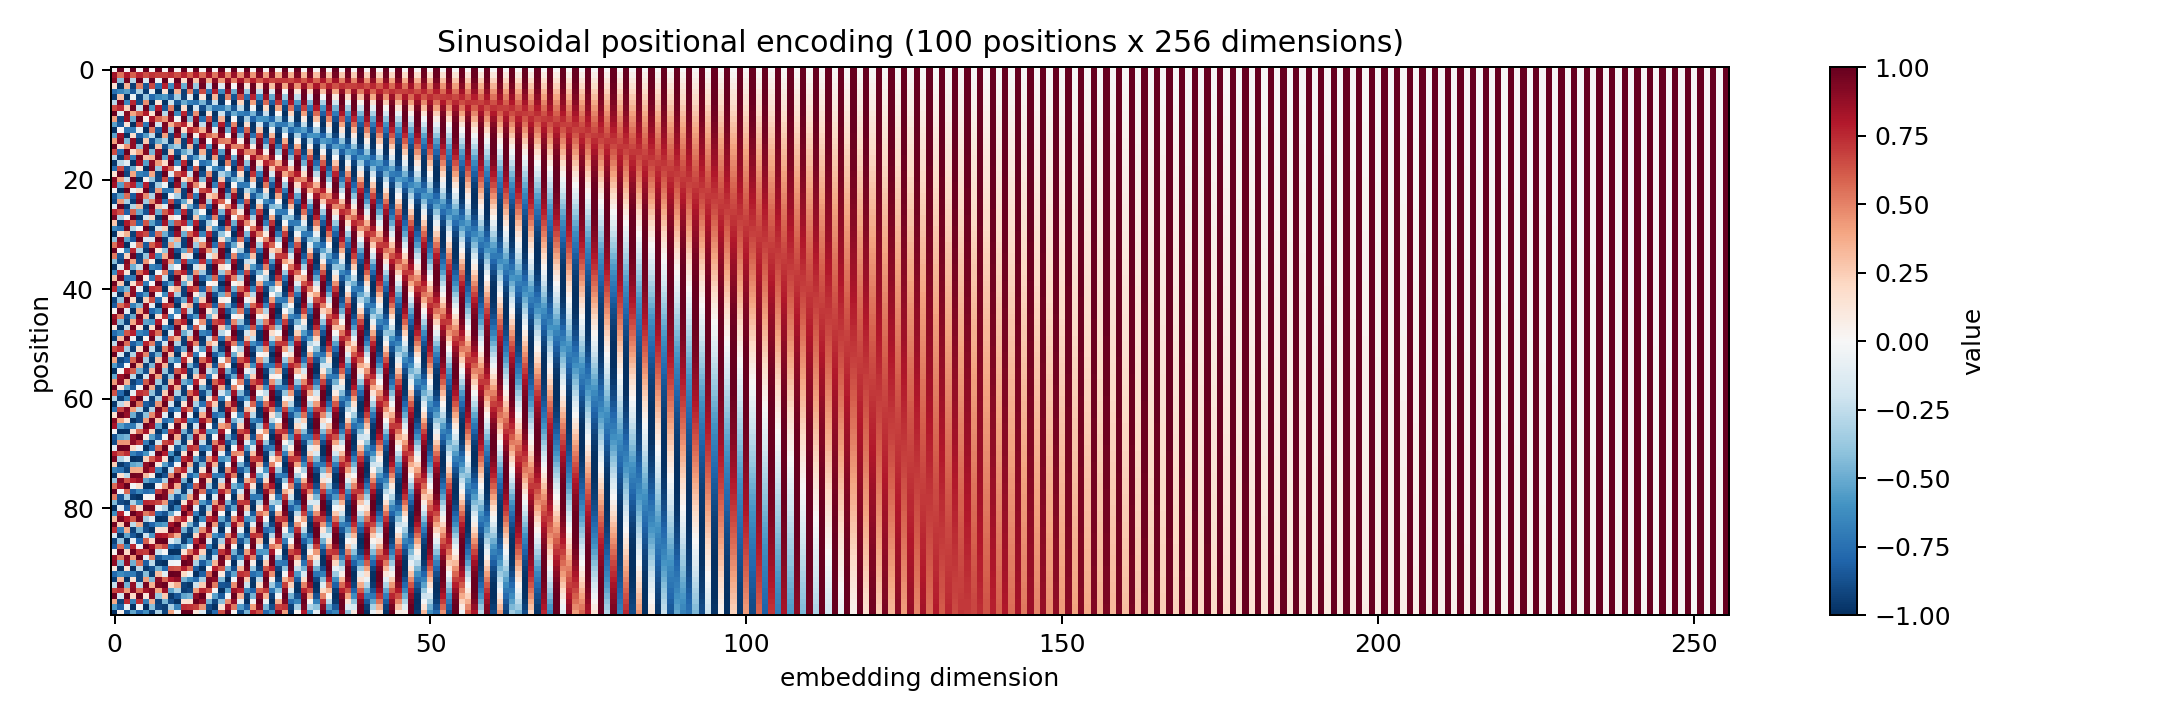

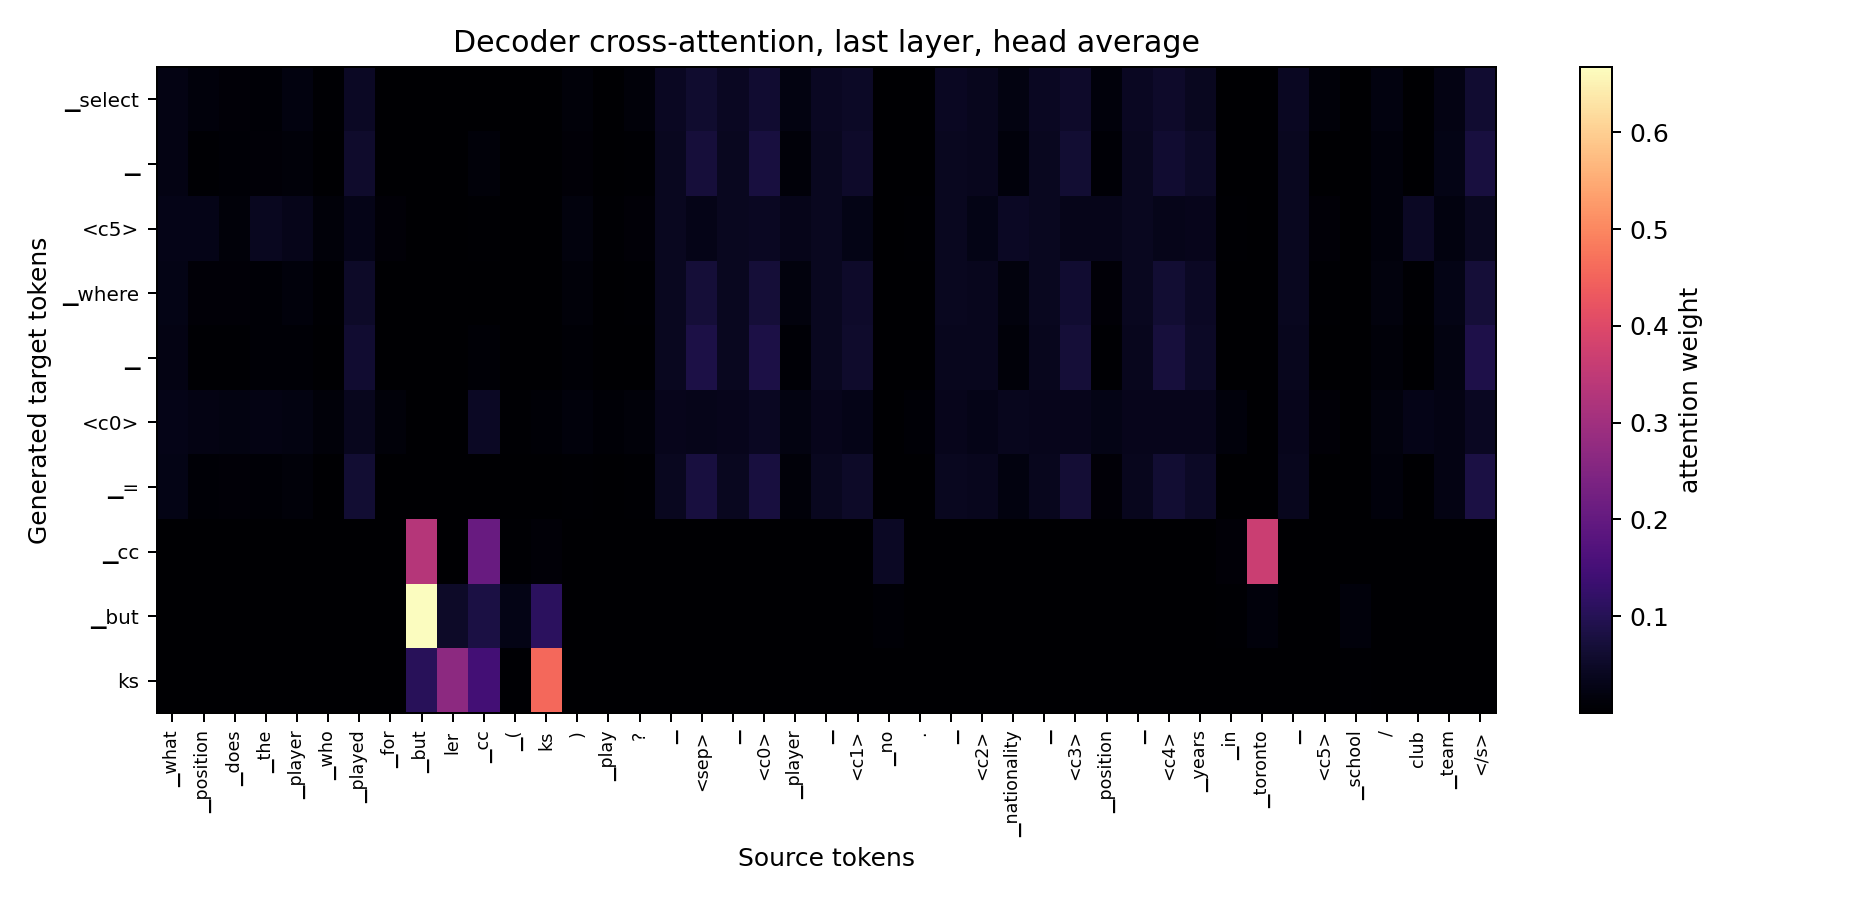

In [30]:
from IPython.display import display, Image

display(Image(filename="evaluation/positional_encoding.png"))
display(Image(filename="evaluation/cross_attention_dev.png"))

In [31]:
from IPython.display import display, Markdown

with open("evaluation/analysis_report.md", "r", encoding="utf-8") as f:
    report = f.read()

display(Markdown(report))

# Text-to-SQL analysis

## Starter statistics

| Split | Pairs | Source mean | Source max | Target mean | Target max |
|---|---:|---:|---:|---:|---:|
| train | 56,355 | 41.55 | 221 | 12.77 | 63 |
| dev | 8,421 | 41.49 | 166 | 12.79 | 42 |
| test | 15,878 | 41.67 | 259 | 12.93 | 44 |

## Model facts

- Trainable parameters: **7,585,600**.
- Configuration: d_model=256, heads=4, encoder/decoder layers=3/3, feed-forward size=1024, dropout=0.1, post-norm LayerNorm.
- `starter/check_starter.py` reports `(B, S)` and `(B, T)` token batches, followed by `(B, S, 256)` and `(B, T-1, 256)` embeddings.

## Positional encoding

The heatmap shows alternating sinusoidal patterns across positions and embedding dimensions. Low-frequency dimensions change slowly while high-frequency dimensions change rapidly, giving every position a distinct representation that can be extrapolated beyond training positions.

## Cross-attention

Generated figure: `cross_attention_dev.png`. It averages the heads from the final decoder layer for one dev example.


**Download**

In [33]:
from google.colab import files

files.download("evaluation/positional_encoding.png")
files.download("evaluation/cross_attention_dev.png")
files.download("evaluation/analysis_report.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Official WikiSQL Evaluation Results**

In [34]:
import json
from pathlib import Path

for name in ["greedy", "beam"]:
    path = Path(f"results/dev_{name}_metrics.json")
    if path.exists():
        with open(path, "r", encoding="utf-8") as f:
            metrics = json.load(f)

        print(f"\n{name.upper()} EVALUATION")
        print(json.dumps(metrics, indent=2))


GREEDY EVALUATION
{
  "split": "dev",
  "strategy": "greedy",
  "examples": 8421,
  "parse_failure_rate": 0.002850017812611294,
  "select_column_exact": 0.3041206507540672,
  "aggregation_exact": 0.8802992518703242,
  "conditions_exact": 0.21434508965681034
}

BEAM EVALUATION
{
  "split": "dev",
  "strategy": "beam",
  "examples": 8421,
  "parse_failure_rate": 0.0022562641016505847,
  "select_column_exact": 0.3062581641135257,
  "aggregation_exact": 0.8800617503859399,
  "conditions_exact": 0.22812017575109844
}


**Compare Official Dev Accuracy**

In [35]:
from pathlib import Path
import subprocess

for strategy in ["greedy", "beam"]:
    predictions = f"results/dev_{strategy}_predictions.jsonl"

    print(f"\n{strategy.upper()} Official WikiSQL Evaluation")
    result = subprocess.run(
        [
            "python", "WikiSQL/evaluate.py",
            "WikiSQL/data/dev.jsonl",
            "WikiSQL/data/dev.db",
            predictions
        ],
        capture_output=True,
        text=True
    )

    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)


GREEDY Official WikiSQL Evaluation
{
  "ex_accuracy": 0.1629260182876143,
  "lf_accuracy": 0.09084431777698611
}


BEAM Official WikiSQL Evaluation
{
  "ex_accuracy": 0.17111981949887187,
  "lf_accuracy": 0.09393183707398171
}



**Inspect Prediction Errors**

In [36]:
import json
from pathlib import Path

gold_path = Path("WikiSQL/data/dev.jsonl")
pred_path = Path("results/dev_beam_predictions.jsonl")

with open(gold_path, encoding="utf-8") as f:
    gold = [json.loads(line) for line in f]

with open(pred_path, encoding="utf-8") as f:
    preds = [json.loads(line) for line in f]

print("Gold examples:", len(gold))
print("Predictions:", len(preds))
print("\nFirst prediction record:")
print(json.dumps(preds[0], indent=2)[:3000])

print("\nFirst gold record:")
print(json.dumps(gold[0], indent=2)[:3000])

Gold examples: 8421
Predictions: 8421

First prediction record:
{
  "query": {
    "sel": 5,
    "agg": 0,
    "conds": [
      [
        0,
        0,
        "cc butksler"
      ]
    ]
  }
}

First gold record:
{
  "phase": 1,
  "table_id": "1-10015132-11",
  "question": "What position does the player who played for butler cc (ks) play?",
  "sql": {
    "sel": 3,
    "conds": [
      [
        5,
        0,
        "Butler CC (KS)"
      ]
    ],
    "agg": 0
  }
}


**Compare Gold and Predicted SQL**

In [37]:
import json

with open("WikiSQL/data/dev.jsonl", encoding="utf-8") as f:
    gold = [json.loads(line) for line in f]

with open("results/dev_beam_predictions.jsonl", encoding="utf-8") as f:
    preds = [json.loads(line) for line in f]

for i in range(5):
    g = gold[i]
    p = preds[i]["query"]
    sql = g["sql"]

    print(f"\nExample {i + 1}")
    print("Question:", g["question"])
    print("Gold SELECT:", sql["sel"], "| Predicted SELECT:", p["sel"])
    print("Gold AGG:", sql["agg"], "| Predicted AGG:", p["agg"])
    print("Gold conditions:", sql["conds"])
    print("Predicted conditions:", p["conds"])
    print("-" * 60)


Example 1
Question: What position does the player who played for butler cc (ks) play?
Gold SELECT: 3 | Predicted SELECT: 5
Gold AGG: 0 | Predicted AGG: 0
Gold conditions: [[5, 0, 'Butler CC (KS)']]
Predicted conditions: [[0, 0, 'cc butksler']]
------------------------------------------------------------

Example 2
Question: How many schools did player number 3 play at?
Gold SELECT: 5 | Predicted SELECT: 3
Gold AGG: 3 | Predicted AGG: 3
Gold conditions: [[1, 0, '3']]
Predicted conditions: [[5, 0, '3']]
------------------------------------------------------------

Example 3
Question: What school did player number 21 play for?
Gold SELECT: 5 | Predicted SELECT: 0
Gold AGG: 0 | Predicted AGG: 0
Gold conditions: [[1, 0, '21']]
Predicted conditions: [[5, 0, '21']]
------------------------------------------------------------

Example 4
Question: Who is the player that wears number 42?
Gold SELECT: 0 | Predicted SELECT: 0
Gold AGG: 0 | Predicted AGG: 0
Gold conditions: [[1, 0, '42']]
Predicte

**Inspect Preprocessed Input and Target**

In [38]:
import json

with open("data/dev_pairs.jsonl", encoding="utf-8") as f:
    pairs = [json.loads(line) for line in f]

print("Preprocessed example:")
print(json.dumps(pairs[0], indent=2, ensure_ascii=False))

Preprocessed example:
{
  "table_id": "1-10015132-11",
  "src": "what position does the player who played for butler cc (ks) play? <sep> <c0> player <c1> no. <c2> nationality <c3> position <c4> years in toronto <c5> school/club team",
  "tgt": "select  <c3>  where  <c5> = butler cc (ks)"
}


**Inspect Original Table Columns**

In [39]:
import json

with open("WikiSQL/data/dev.jsonl", encoding="utf-8") as f:
    gold = [json.loads(line) for line in f]

with open("WikiSQL/data/dev.tables.jsonl", encoding="utf-8") as f:
    tables = {
        table["id"]: table
        for table in map(json.loads, f)
    }

example = gold[0]
table = tables[example["table_id"]]

print("Question:", example["question"])
print("\nColumn headers:")
for i, header in enumerate(table["header"]):
    print(i, repr(header))

print("\nGold SQL:", example["sql"])

Question: What position does the player who played for butler cc (ks) play?

Column headers:
0 'Player'
1 'No.'
2 'Nationality'
3 'Position'
4 'Years in Toronto'
5 'School/Club Team'

Gold SQL: {'sel': 3, 'conds': [[5, 0, 'Butler CC (KS)']], 'agg': 0}


**Verify Tokenizer Decoding**

In [40]:
import sentencepiece as spm

sp = spm.SentencePieceProcessor(model_file="data/sql_sp.model")

print("Vocabulary size:", sp.get_piece_size())

for text in [
    "Butler CC (KS)",
    "butler cc (ks)",
    "1996-97",
    "School/Club Team"
]:
    ids = sp.encode(text, out_type=int)
    decoded = sp.decode(ids)

    print("\nOriginal:", repr(text))
    print("Token IDs:", ids)
    print("Decoded:", repr(decoded))

Vocabulary size: 8000

Original: 'Butler CC (KS)'
Token IDs: [6974, 1, 303, 1721, 6974, 7516, 7516, 133, 1, 7006]
Decoded: ' ⁇ utler CC ( ⁇ )'

Original: 'butler cc (ks)'
Token IDs: [2944, 1721, 3194, 133, 1736, 7006]
Decoded: 'butler cc (ks)'

Original: '1996-97'
Token IDs: [1268, 1418, 7012]
Decoded: '1996-97'

Original: 'School/Club Team'
Token IDs: [6974, 1, 4981, 7014, 7516, 6984, 264, 6974, 1, 6975, 91]
Decoded: ' ⁇ chool/Club  ⁇ eam'


**Check Unknown Token Frequency**

In [41]:
import json
from collections import Counter

import sentencepiece as spm

sp = spm.SentencePieceProcessor(model_file="data/sql_sp.model")
unk_id = sp.unk_id()

texts = []

with open("data/dev_pairs.jsonl", encoding="utf-8") as f:
    for line in f:
        pair = json.loads(line)
        texts.append(pair["src"])
        texts.append(pair["tgt"])

total_tokens = 0
unknown_tokens = 0

for text in texts:
    ids = sp.encode(text, out_type=int)
    total_tokens += len(ids)
    unknown_tokens += sum(token_id == unk_id for token_id in ids)

print("Total encoded tokens:", total_tokens)
print("Unknown tokens:", unknown_tokens)
print("Unknown token rate:", round(100 * unknown_tokens / max(total_tokens, 1), 4), "%")

Total encoded tokens: 457074
Unknown tokens: 129
Unknown token rate: 0.0282 %


Check Tokenixer Special IDs

In [42]:
print("PAD ID:", sp.pad_id())
print("UNK ID:", sp.unk_id())
print("BOS ID:", sp.bos_id())
print("EOS ID:", sp.eos_id())

for text in ["Butler", "School", "Team", "Position", "butler"]:
    ids = sp.encode(text, out_type=int)
    print(repr(text), "->", ids, "->", repr(sp.decode(ids)))

PAD ID: 0
UNK ID: 1
BOS ID: 2
EOS ID: 3
'Butler' -> [6974, 1, 303, 1721] -> ' ⁇ utler'
'School' -> [6974, 1, 4981] -> ' ⁇ chool'
'Team' -> [6974, 1, 6975, 91] -> ' ⁇ eam'
'Position' -> [6974, 1, 417, 185] -> ' ⁇ osition'
'butler' -> [2944, 1721] -> 'butler'


**Check Unknown Tokens in Predictions**

In [43]:
import json
import sentencepiece as spm
from collections import Counter

sp = spm.SentencePieceProcessor(model_file="data/sql_sp.model")
unk_id = sp.unk_id()

with open("results/dev_beam_predictions.jsonl", encoding="utf-8") as f:
    predictions = [json.loads(line) for line in f]

unknown_count = 0
total_count = 0
examples_with_unk = []

for i, record in enumerate(predictions):
    text = json.dumps(record, ensure_ascii=False)
    ids = sp.encode(text, out_type=int)

    count = sum(token_id == unk_id for token_id in ids)
    unknown_count += count
    total_count += len(ids)

    if count and len(examples_with_unk) < 10:
        examples_with_unk.append((i, text, count))

print("Prediction tokens:", total_count)
print("Unknown tokens:", unknown_count)
print("Unknown token rate:", round(100 * unknown_count / max(total_count, 1), 4), "%")

print("\nExamples containing unknown tokens:")
for i, text, count in examples_with_unk:
    print(f"\nExample {i} | UNK count: {count}")
    print(text)

Prediction tokens: 349028
Unknown tokens: 0
Unknown token rate: 0.0 %

Examples containing unknown tokens:


**Inspect Model Prediction Decoding**

In [44]:
import json
from pathlib import Path

import sentencepiece as spm
from evaluate_model import build_model

sp = spm.SentencePieceProcessor(model_file="data/sql_sp.model")

checkpoint = Path("best_model.pt")
print("Checkpoint exists:", checkpoint.exists())
print("Tokenizer vocabulary:", sp.get_piece_size())

with open("data/dev_pairs.jsonl", encoding="utf-8") as f:
    pairs = [json.loads(line) for line in f]

for i in range(3):
    print(f"\nExample {i + 1}")
    print("Source:", pairs[i]["src"])
    print("Target:", pairs[i]["tgt"])

Checkpoint exists: True
Tokenizer vocabulary: 8000

Example 1
Source: what position does the player who played for butler cc (ks) play? <sep> <c0> player <c1> no. <c2> nationality <c3> position <c4> years in toronto <c5> school/club team
Target: select  <c3>  where  <c5> = butler cc (ks)

Example 2
Source: how many schools did player number 3 play at? <sep> <c0> player <c1> no. <c2> nationality <c3> position <c4> years in toronto <c5> school/club team
Target: select  count  <c5>  where  <c1> = 3

Example 3
Source: what school did player number 21 play for? <sep> <c0> player <c1> no. <c2> nationality <c3> position <c4> years in toronto <c5> school/club team
Target: select  <c5>  where  <c1> = 21


**Inspect SQL Decoding Implementation**

In [45]:
from pathlib import Path

files_to_check = [
    "evaluate_model.py",
    "starter/tokenizer.py",
    "model/transformer.py",
    "model/attention.py"
]

for filename in files_to_check:
    path = Path(filename)
    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    if path.exists():
        lines = path.read_text(encoding="utf-8").splitlines()

        for i, line in enumerate(lines, start=1):
            if any(word in line.lower() for word in [
                "decode", "generate", "greedy", "beam",
                "parse", "tokenizer", "sentencepiece"
            ]):
                print(f"{i}: {line}")


==================== evaluate_model.py ====================
1: """Decode a split and write WikiSQL prediction files.
4: Malformed generations are written as {"error": "parse"}.
11: Task 5.2 plus the parse-failure rate.
14: import argparse
22: import sentencepiece as spm
26: from decode import beam_search, greedy_decode, parse_prediction
30: from starter.tokenizer import PAD_ID, read_pairs
33: DEFAULT_TOKENIZER = "data/sql_sp.model"
81: def decode_example(model, pair, sp, device, strategy, beam_size):
87:     if strategy == "beam":
88:         token_ids = beam_search(
92:             beam_size=beam_size,
94:         return token_ids, sp.decode(token_ids)
95:     return greedy_decode(model, src_ids, sp, device)
118: def decode_split(model, pairs, sp, device, strategy, beam_size):
119:     """Decode every pair, returning per-example records and component totals."""
121:         "parse_valid": 0,
130:         _, predicted = decode_example(model, pair, sp, device, strategy, beam_size)
131:

**Inspect Decoding and Parsing Functions**

In [46]:
from pathlib import Path

for filename, start, end in [
    ("decode.py", 1, 240),
    ("evaluate_model.py", 75, 155),
]:
    print(f"\n{'=' * 20} {filename} {'=' * 20}")
    lines = Path(filename).read_text(encoding="utf-8").splitlines()

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")


==================== decode.py ====================
1: import re
2: import torch
3: 
4: from starter.tokenizer import (BOS_ID, EOS_ID)
5: from starter.data_prep import (AGG_OPS,COND_OPS)
6: 
7: MAX_DECODE_LEN = 64
8: BEAM_SIZE = 4
9: 
10: # GNMT-style length penalty exponent. Without it the raw sum of log-probs
11: # always favours the shortest hypothesis, so an immediate </s> (an empty
12: # target string) outranks every complete query and the parser rejects it.
13: BEAM_LENGTH_PENALTY = 0.7
14: 
15: # A completed hypothesis needs at least this many content tokens to be a
16: # parseable query ("select <c0>" is already 2).
17: MIN_CONTENT_TOKENS = 2
18: 
19: 
20: def is_eos(token_id):
21:     return token_id == EOS_ID
22: 
23: 
24: def beam_length_penalty(num_generated_tokens, alpha=BEAM_LENGTH_PENALTY):
25:     """Normalise a cumulative log-prob by sequence length (GNMT, Eq. 14)."""
26:     if num_generated_tokens <= 0:
27:         return float("-inf")
28:     return num_generated_t

**Inspect Actual Decoded SQL**

In [50]:
import json
import sentencepiece as spm
import torch

from evaluate_model import build_model
from decode import greedy_decode, beam_search

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sp = spm.SentencePieceProcessor(model_file="data/sql_sp.model")

checkpoint = torch.load(
    "best_model.pt",
    map_location=device,
    weights_only=False
)

model = build_model(checkpoint, sp, device)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

with open("data/dev_pairs.jsonl", encoding="utf-8") as f:
    pairs = [json.loads(line) for line in f]

for i in range(5):
    pair = pairs[i]
    src_ids = torch.tensor(
        [sp.encode(pair["src"], out_type=int)],
        dtype=torch.long,
        device=device
    )

    _, greedy_text = greedy_decode(model, src_ids, sp, device)
    beam_ids = beam_search(model, src_ids, device, beam_size=4)
    beam_text = sp.decode(beam_ids)

    print(f"\nExample {i + 1}")
    print("Gold:  ", pair["tgt"])
    print("Greedy:", greedy_text)
    print("Beam:  ", beam_text)


Example 1
Gold:   select  <c3>  where  <c5> = butler cc (ks)
Greedy: select <c5> where <c0> = cc butks
Beam:   select <c5> where <c0> = cc butksler

Example 2
Gold:   select  count  <c5>  where  <c1> = 3
Greedy: select count <c1> where <c0> = 3
Beam:   select count <c3> where <c5> = 3

Example 3
Gold:   select  <c5>  where  <c1> = 21
Greedy: select <c0> where <c5> = 21
Beam:   select <c0> where <c5> = 21

Example 4
Gold:   select  <c0>  where  <c1> = 42
Greedy: select <c0> where <c5> = 42
Beam:   select <c0> where <c5> = 42

Example 5
Gold:   select  <c0>  where  <c3> = guard and <c4> = 1996-97
Greedy: select <c0> where <c3> = guard and <c2> = 1996-97
Beam:   select <c0> where <c3> = guard and <c2> = 1996-97


**Check Training Checkpoint and Model Configuration**

In [51]:
import torch
import json

checkpoint = torch.load(
    "best_model.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Global step:", checkpoint.get("global_step"))
print("Training loss:", checkpoint.get("train_loss"))
print("Dev loss:", checkpoint.get("dev_loss"))
print("Best dev loss:", checkpoint.get("best_dev_loss"))

print("\nModel configuration:")
print(json.dumps(checkpoint.get("config", {}), indent=2))

Checkpoint epoch: 11
Global step: 18784
Training loss: 1.779078752665544
Dev loss: 2.1059217141433195
Best dev loss: 2.1059217141433195

Model configuration:
{
  "d_model": 256,
  "heads": 4,
  "d_ff": 1024,
  "num_layers": 3,
  "dropout": 0.1,
  "warmup_steps": 4000,
  "label_smoothing": 0.1
}


**Check Model and Tokenizer Vocabulary Alignment**

In [53]:
import torch

print("Tokenizer vocabulary size:", sp.get_piece_size())
print("Output projection vocabulary size:", model.output_projection.weight.shape[0])

print("\nEmbedding layers:")
for name, module in model.named_modules():
    if isinstance(module, torch.nn.Embedding):
        print(
            f"Name: {name} | "
            f"Vocabulary size: {module.num_embeddings} | "
            f"Embedding dimension: {module.embedding_dim}"
        )

Tokenizer vocabulary size: 8000
Output projection vocabulary size: 8000

Embedding layers:
Name: encoder.input.tok.emb | Vocabulary size: 8000 | Embedding dimension: 256


**Check Training Files**

In [54]:
from pathlib import Path

for folder in ["results", "checkpoints", "models", "logs"]:
    path = Path(folder)
    if path.exists():
        print(f"\n{folder}/")
        for item in sorted(path.iterdir()):
            print(item.name)


results/
analysis.json
analysis_report.md
cross_attention_dev.png
dev_beam_metrics.json
dev_beam_predictions.jsonl
dev_greedy_metrics.json
dev_greedy_partial5_metrics.json
dev_greedy_partial5_predictions.jsonl
dev_greedy_predictions.jsonl
positional_encoding.png


**Inspect Training Configuration**

In [55]:
from pathlib import Path

for filename in ["train.py", "starter/train.py", "training.py"]:
    path = Path(filename)
    if path.exists():
        print(f"\n{'=' * 15} {filename} {'=' * 15}")
        lines = path.read_text(encoding="utf-8").splitlines()
        for i, line in enumerate(lines, start=1):
            if any(word in line.lower() for word in [
                "epoch", "batch_size", "warmup", "optimizer",
                "checkpoint", "resume", "save", "dev_loss"
            ]):
                print(f"{i}: {line}")


=============== train.py ===============
23: BATCH_SIZE = 64
24: EPOCHS = 20
26: WARMUP_STEPS = 4000
34: BEST_CHECKPOINT = "best_model.pt"
35: LAST_CHECKPOINT = "last_model.pt"
36: RESUME_CHECKPOINT = None
43: def transformer_lr(step, d_model, warmup_steps):
51:                 step * warmup_steps^(-1.5)
62:             step * warmup_steps ** -1.5
83: def train_one_epoch(model, loader, criterion, optimizer, device, global_step):
95:         lr = transformer_lr( global_step, D_MODEL, WARMUP_STEPS)
96:         for param_group in optimizer.param_groups:
102:         optimizer.zero_grad()
105:         optimizer.step()
111:     current_lr = optimizer.param_groups[0]["lr"]
115: def build_checkpoint(
116:     epoch,
119:     optimizer,
121:     dev_loss,
125:         "epoch": epoch,
128:         "optimizer_state_dict": optimizer.state_dict(),
130:         "dev_loss": dev_loss,
138:             "warmup_steps": WARMUP_STEPS,
140:             "batch_size": BATCH_SIZE,
141:             "epochs":

**Verify Training Checkpoints**

In [56]:
from pathlib import Path
import torch

for filename in ["best_model.pt", "last_model.pt"]:
    path = Path(filename)

    print(f"\n{filename}")
    print("Exists:", path.exists())

    if path.exists():
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Epoch:", checkpoint.get("epoch"))
        print("Global step:", checkpoint.get("global_step"))
        print("Train loss:", checkpoint.get("train_loss"))
        print("Dev loss:", checkpoint.get("dev_loss"))
        print("Best dev loss:", checkpoint.get("best_dev_loss"))


best_model.pt
Exists: True
Epoch: 11
Global step: 18784
Train loss: 1.779078752665544
Dev loss: 2.1059217141433195
Best dev loss: 2.1059217141433195

last_model.pt
Exists: False


**Check Training Resume Configuration**

In [57]:
from pathlib import Path

print("Training script exists:", Path("train.py").exists())
print("Best checkpoint exists:", Path("best_model.pt").exists())
print("Last checkpoint exists:", Path("last_model.pt").exists())

if Path("train.py").exists():
    lines = Path("train.py").read_text(encoding="utf-8").splitlines()

    for start, end in [(15, 40), (180, 225), (250, 275)]:
        print(f"\n--- train.py lines {start}-{end} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1}: {lines[i]}")

Training script exists: True
Best checkpoint exists: True
Last checkpoint exists: False

--- train.py lines 15-40 ---
15: VOCAB_SIZE = None
16: D_MODEL = 256
17: HEADS = 4
18: D_FF = 1024
19: NUM_LAYERS = 3
20: MAX_LEN = 512
21: DROPOUT = 0.1
22: 
23: BATCH_SIZE = 64
24: EPOCHS = 20
25: 
26: WARMUP_STEPS = 4000
27: LABEL_SMOOTHING = 0.1
28: MAX_GRAD_NORM = 1.0
29: 
30: LEARNING_RATE_EPS = 1e-9
31: BETA1 = 0.9
32: BETA2 = 0.98
33: 
34: BEST_CHECKPOINT = "best_model.pt"
35: LAST_CHECKPOINT = "last_model.pt"
36: RESUME_CHECKPOINT = None
37: TRAIN_LOG = Path("results/train_log.jsonl")
38: 
39: TRAIN_PATH = "data/train_pairs.jsonl"
40: DEV_PATH = "data/dev_pairs.jsonl"

--- train.py lines 180-225 ---
180:         label_smoothing=LABEL_SMOOTHING
181:     )
182:     optimizer = torch.optim.Adam(
183:         model.parameters(),
184:         lr=0.0,
185:         betas=(BETA1, BETA2),
186:         eps=LEARNING_RATE_EPS
187:     )
188: 
189:     start_epoch = 1
190:     global_step = 0
191:     

**Backup Best Checkpoint**

In [58]:
from pathlib import Path
import shutil

source = Path("best_model.pt")
backup = Path("best_model_epoch11_backup.pt")

if source.exists() and not backup.exists():
    shutil.copy2(source, backup)

print("Original checkpoint:", source.exists())
print("Backup checkpoint:", backup.exists())

Original checkpoint: True
Backup checkpoint: True


**Configure Training Resume**

In [59]:
from pathlib import Path

path = Path("train.py")
text = path.read_text(encoding="utf-8")

old = "RESUME_CHECKPOINT = None"
new = 'RESUME_CHECKPOINT = "best_model.pt"'

if old not in text:
    raise ValueError("Expected resume setting not found; train.py was not changed.")

path.write_text(text.replace(old, new, 1), encoding="utf-8")

print("Resume configured:", 'RESUME_CHECKPOINT = "best_model.pt"' in path.read_text(encoding="utf-8"))

Resume configured: True


In [60]:
from pathlib import Path
import re

text = Path("train.py").read_text(encoding="utf-8")

for pattern in [
    r"RESUME_CHECKPOINT\s*=.*",
    r"BEST_CHECKPOINT\s*=.*",
    r"LAST_CHECKPOINT\s*=.*",
    r"EPOCHS\s*=.*",
    r"BATCH_SIZE\s*=.*",
]:
    match = re.search(pattern, text)
    print(match.group(0) if match else f"Not found: {pattern}")

RESUME_CHECKPOINT = "best_model.pt"
BEST_CHECKPOINT = "best_model.pt"
LAST_CHECKPOINT = "last_model.pt"
EPOCHS = 20
BATCH_SIZE = 64


**Resume Training from Epoch 11**

In [61]:
%cd /content/text-2-SQL-scratch
!python train.py

/content/text-2-SQL-scratch
Device: cuda
GPU: Tesla T4
Vocabulary size: 8000
data/train_pairs.jsonl: kept 56336, skipped 19
data/dev_pairs.jsonl: kept 8421, skipped 0
Trainable parameters: 7585600
Resumed from best_model.pt: epoch 11, global step 18784, dev loss 2.1059
Epoch 12/20 | Train Loss: 2.1274 | Dev Loss: 2.1870 | LR: 0.00044569 | Grad Norm: 2.2359 | 60.35s
Epoch 13/20 | Train Loss: 1.8458 | Dev Loss: 2.1678 | LR: 0.00043603 | Grad Norm: 2.5781 | 65.68s
Epoch 14/20 | Train Loss: 1.7973 | Dev Loss: 2.1522 | LR: 0.00042697 | Grad Norm: 1.9699 | 67.99s
Epoch 15/20 | Train Loss: 1.7658 | Dev Loss: 2.1443 | LR: 0.00041846 | Grad Norm: 1.8338 | 68.39s
Epoch 16/20 | Train Loss: 1.7434 | Dev Loss: 2.1263 | LR: 0.00041043 | Grad Norm: 1.8835 | 67.71s
Epoch 17/20 | Train Loss: 1.7219 | Dev Loss: 2.1291 | LR: 0.00040285 | Grad Norm: 2.1137 | 67.67s
Epoch 18/20 | Train Loss: 1.7047 | Dev Loss: 2.1047 | LR: 0.00039567 | Grad Norm: 1.8407 | 67.64s
  Saved checkpoint: best_model.pt
Epoch 19/2

**Verify Final Training Checkpoints**

In [62]:
import torch
from pathlib import Path

for filename in ["best_model.pt", "last_model.pt"]:
    path = Path(filename)
    print(f"\n{filename}: Exists = {path.exists()}")

    if path.exists():
        ckpt = torch.load(
            filename,
            map_location="cpu",
            weights_only=False
        )
        print("Epoch:", ckpt.get("epoch"))
        print("Global step:", ckpt.get("global_step"))
        print("Train loss:", ckpt.get("train_loss"))
        print("Dev loss:", ckpt.get("dev_loss"))
        print("Best dev loss:", ckpt.get("best_dev_loss"))


best_model.pt: Exists = True
Epoch: 18
Global step: 24951
Train loss: 1.7047451154057203
Dev loss: 2.1047481045578467
Best dev loss: 2.1047481045578467

last_model.pt: Exists = True
Epoch: 20
Global step: 26713
Train loss: 1.673587596781814
Dev loss: 2.117395184256814
Best dev loss: 2.1047481045578467


**Re-evaluate Best Checkpoint on Dev Set**

In [63]:
%cd /content/text-2-SQL-scratch

!python evaluate_model.py \
    --checkpoint best_model.pt \
    --split data/dev_pairs.jsonl \
    --strategy greedy

/content/text-2-SQL-scratch
data/dev_pairs.jsonl: kept 8421, skipped 0
Device: cuda
Checkpoint: best_model.pt
Checkpoint epoch: 18
Examples: 8421
Teacher-forced loss: 2.1057
Perplexity: 8.2127
Teacher-forced token accuracy: 77.19%
Parse-failure rate: 0.43%
sel column exact: 34.91%
agg exact: 88.16%
WHERE clause exact: 23.82%
Official logical-form accuracy: 12.40%
Official execution accuracy: 19.49%
Strategy: greedy
Trainable parameters: 7,585,600
Predictions: results/dev_greedy_predictions.jsonl
Metrics: results/dev_greedy_metrics.json


**Evaluate Beam Search on Dev Set**

In [64]:
!python evaluate_model.py \
    --checkpoint best_model.pt \
    --split data/dev_pairs.jsonl \
    --strategy beam \
    --beam-size 4 \
    --skip-official

data/dev_pairs.jsonl: kept 8421, skipped 0
Device: cuda
Checkpoint: best_model.pt
Checkpoint epoch: 18
Examples: 8421
Teacher-forced loss: 2.1057
Perplexity: 8.2127
Teacher-forced token accuracy: 77.19%
Parse-failure rate: 0.34%
sel column exact: 34.91%
agg exact: 87.77%
WHERE clause exact: 25.29%
Official metrics: not available (run WikiSQL/evaluate.py separately)
Strategy: beam
Trainable parameters: 7,585,600
Predictions: results/dev_beam_predictions.jsonl
Metrics: results/dev_beam_metrics.json


**Official Beam Evaluation on Dev Set**

In [65]:
%cd /content/text-2-SQL-scratch

!python WikiSQL/evaluate.py \
    WikiSQL/data/dev.jsonl \
    WikiSQL/data/dev.db \
    results/dev_beam_predictions.jsonl

/content/text-2-SQL-scratch
100% 8421/8421 [00:10<00:00, 778.73it/s]
{
  "ex_accuracy": 0.20258876617978863,
  "lf_accuracy": 0.12943830898943118
}


In [ ]:
Generate Final Cross-Attention Heatmap

In [66]:
%cd /content/text-2-SQL-scratch
!python analysis.py

/content/text-2-SQL-scratch
Wrote analysis artifacts to evaluation


**Verify Final Analysis Artifacts**

In [67]:
from pathlib import Path

for filename in [
    "evaluation/positional_encoding.png",
    "evaluation/cross_attention_dev.png",
    "evaluation/analysis.json",
    "evaluation/analysis_report.md",
]:
    path = Path(filename)
    print(f"{filename}: {'Ready' if path.exists() else 'Missing'}")

evaluation/positional_encoding.png: Ready
evaluation/cross_attention_dev.png: Ready
evaluation/analysis.json: Ready
evaluation/analysis_report.md: Ready


**Final Test Evaluation — Beam Searc**

In [ ]:
%cd /content/text-2-SQL-scratch

!python evaluate_model.py \
    --checkpoint best_model.pt \
    --split data/test_pairs.jsonl \
    --strategy beam \
    --beam-size 4

/content/text-2-SQL-scratch
data/test_pairs.jsonl: kept 15878, skipped 0


In [2]:
import os
import torch

PROJECT = "/content/text-2-SQL-scratch"

print("GPU available:", torch.cuda.is_available())
print("Project exists:", os.path.isdir(PROJECT))

if os.path.isdir(PROJECT):
    os.chdir(PROJECT)
    for f in [
        "best_model.pt",
        "last_model.pt",
        "best_model_epoch11_backup.pt",
        "evaluation/analysis.json",
        "evaluation/cross_attention_dev.png",
        "evaluation/positional_encoding.png",
        "results/dev_beam_predictions.jsonl",
        "results/dev_beam_metrics.json",
    ]:
        print(f, "->", os.path.exists(f))

GPU available: False
Project exists: False
